In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [ ]:
# load dataset from seaborn
# this dataset is originally collected from real car data
data  = sns.load_dataset("mpg")
data.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


# learing about the dataset
# MPG =mileade per gallon
 # high mpg --> consumes less fuel
 # low mpg  --> consume more fuel
# why is it popular for
     # 1.data visualizaation
     # 2.linear regression
    #  3.corelation analysis
    #  4.understanding realtionship




In [ ]:
# Basic data cleaning
# we will use horse power to predict mpg
data = data[["horsepower","mpg"]].dropna()
data.shape

(392, 2)

In [ ]:
# data inspection
data.head()


,horsepower,mpg
0,130.0,18.0
1,165.0,15.0
2,150.0,18.0
3,150.0,16.0
4,140.0,17.0


In [ ]:
data.tail()

,horsepower,mpg
393,86.0,27.0
394,52.0,44.0
395,84.0,32.0
396,79.0,28.0
397,82.0,31.0


In [ ]:
data.describe()


,horsepower,mpg
count,392.000000,392.000000
mean,104.469388,23.445918
std,38.491160,7.805007
min,46.000000,9.000000
25%,75.000000,17.000000
50%,93.500000,22.750000
75%,126.000000,29.000000
max,230.000000,46.600000


scatter plot visualization


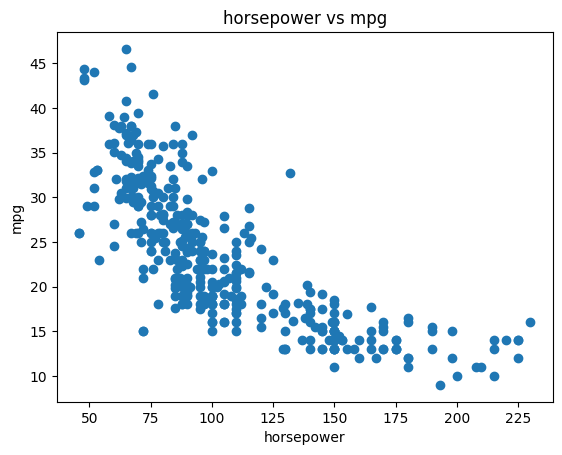

In [ ]:
plt.figure()
plt.scatter(data["horsepower"],data["mpg"])
plt.xlabel("horsepower")
plt.ylabel('mpg')
plt.title("horsepower vs mpg")
plt.show()

TRAINING THE DATASET

In [ ]:
X=data[["horsepower"]]
Y=data["mpg"]

model = LinearRegression()
model.fit(X,Y)

LinearRegression()

VISUALIZE THE BEST FIT LINE

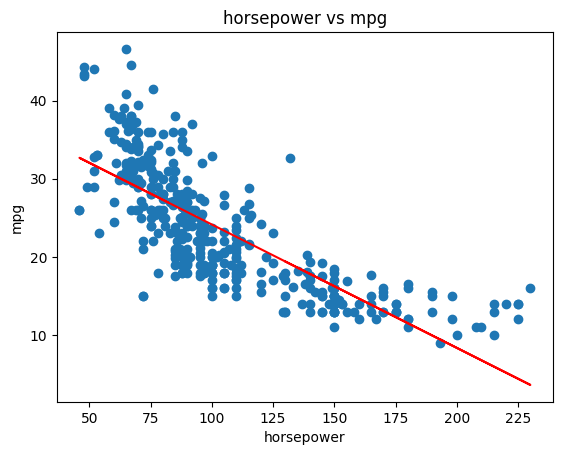

In [ ]:
predicted_mpg = model.predict(X)
plt.figure()
plt.scatter(data["horsepower"],data["mpg"])
plt.plot(X,predicted_mpg,color='red')
plt.xlabel("horsepower")
plt.ylabel("mpg")
plt.title("horsepower vs mpg")
plt.show()

MODEL PARAMETERS (SLOPE AND INTERCEPT)

In [ ]:
# slope
slope = model.coef_[0]
print("slope",slope)

# intercept
intercept = model.intercept_
print("Intercept",intercept)

slope -0.15784473335365365
Intercept 39.93586102117047


cost function - Mean Squared error

In [ ]:
mse = mean_squared_error(Y,predicted_mpg)
print("mse",mse)

mse 23.943662938603108


Evaluation Metrics(RMSE and R2)


In [ ]:
rmse = np.sqrt(mse)
print("rmse",rmse)

r2 = r2_score(Y,predicted_mpg)
print("r^2",r2)

rmse 4.893226230065713
r^2 0.6059482578894348


GRADIENT DESCENT (CONCEPTUAL EXPLANATION USING SKLEARN)

In [ ]:
example_prediction = model.predict([[130]])
print("predicted mpg for 120 horsepower:", example_prediction[0])

predicted mpg for 120 horsepower: 19.416045685195492


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


Residuals analysis

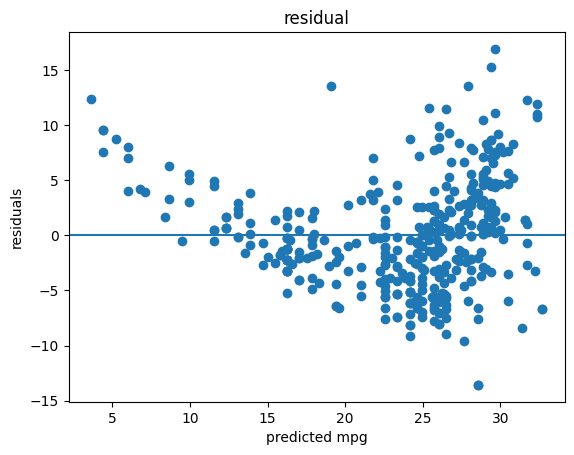

In [ ]:
residuals = Y - predicted_mpg
plt.figure()
plt.scatter(predicted_mpg,residuals)
plt.axhline(y=0)
plt.xlabel("predicted mpg")
plt.ylabel("residuals")
plt.title("residual")
plt.show()